# Speed and accuracy of the thermal phase curve

Where `thermal_PhaseCurve` spends its time, whether its defaults are converged (for the light curve and for the fitted $A_B$ bias), how accurate the fast light-curve path is, and how much faster the SPIDERMAN fork `fspiderman` is than upstream SPIDERMAN. Target: TOI-2431 b in Spitzer/IRAC2; timings depend on the machine.

In [1]:
import time, os, tempfile
import contextlib, io
import numpy as np
import matplotlib.pyplot as plt
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp # faster spiderman with c patches
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve
from hyperphase.phasecurve import custom_temperature_grid, Louden_PhaseCurve, occultation_durations, occultation_window, thermal_PhaseCurve
from hyperphase.orbit import occultation_time
from hyperphase.transit import flux_transit
from joblib.externals.loky import get_reusable_executor  # to recycle SPIDERMAN workers (releases their allocator memory)
from joblib import Parallel, delayed
from hyperphase.bias.fits import fit_naive
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.targets import hi_planets_by_name


In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # the target of the other notebooks
period, incl, ecc, w, r1, r2, R, T_eff, a_AU = planet.args

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # baseline settings (hyperphase/defaults.py)
A_B = DEFAULT_A_B

FILTER_DIR   = os.path.join(os.path.dirname(os.path.abspath('')), 'inputs', 'filters', 'Spiderman')
lambda_range = 1e-6 * np.array([3.6955, 5.1008])                 # Spitzer/IRAC2
filter_path  = os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat")

def bench(fn, warmup=1, repeats=3):
    """Best-of-`repeats` wall time in milliseconds (warm-up excluded)."""
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * min(ts)

def time_tpc(**kw):
    """Time thermal_PhaseCurve with overrides on top of a hyper + filter baseline."""
    p = dict(u=u, u_bol=u_bol, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum")
    p.update(kw)
    return bench(lambda: thermal_PhaseCurve(planet, lambda_range, **p))


# Config for the A_B-bias convergence of section 5, reusing the Spitzer/IRAC2 setup above
l1, l2 = lambda_range
A_B_true = A_B
n_bins = DEFAULT_N_BINS # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min      = 323. # placeholder noise level [ppm]: the bias of section 5 does not depend on it
n_orbits        = DEFAULT_N_ORBITS # number of orbits observed
cfg = FittingConfig(planet=planet, filter_path=filter_path, stellar_model="blackbody",   # blackbody star: the benchmark baseline; FittingConfig derives its stellar grid itself
                 l1=l1, l2=l2, A_=ConstantBandAlbedo(DEFAULT_A),
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=False, u_bol=u_bol, u=u)   # thermal-only phase curve

## 1. Where does the time go?

The exact path of `thermal_PhaseCurve` (`spman="normal"`, `N_LAYERS=60`, 1000 time samples) replicated with a timer per stage, on a 200 × 100 map with a 100 K floor and SPIDERMAN's own blackbody stellar grid (the pipeline: 300 × 150, no floor, `stellar_spidergrid`). The default fast path splits its runtime differently (section 3).

In [3]:
def decompose(n_lo=200, n_la=100, N_LAYERS=60, model="hyperillum", fpath=filter_path, ntime=1000):
    T = {}
    t0=time.perf_counter(); lo,la,tg = custom_temperature_grid(planet, u_bol=u_bol, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B); T["build temperature map (custom_temperature_grid)"]=time.perf_counter()-t0
    t0=time.perf_counter(); LO,LA=np.meshgrid(lo,la,indexing='ij'); grid=sp.format_grid(LO,LA,np.maximum(tg,100.).T); T["format_grid"]=time.perf_counter()-t0
    p=sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody"); p.n_layers=N_LAYERS
    p.t0,p.per=0.,period; p.a_abs=a_AU; p.inc,p.ecc,p.w=incl,ecc,w; p.rp,p.a=r1/r2,R/r2; p.p_u1=p.p_u2=0.
    p.T_s=T_eff; p.grid=grid; p.l1,p.l2=lambda_range; p.filter=fpath
    t0=time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()): sg=sp.stellar_grid.gen_grid(p.l1,p.l2,logg=4.5,response=p.filter,stellar_model="blackbody")   # mutes "no stellar models provided"
    T["stellar grid (gen_grid)"]=time.perf_counter()-t0
    tocc=occultation_time(period, ecc, w, t0=0.)
    t0=time.perf_counter(); p.eclipse=False; p.lightcurve([tocc],stellar_grid=sg); p.eclipse=True; p.lightcurve([tocc],stellar_grid=sg); T["occultation depth (2x lightcurve @ 1 pt)"]=time.perf_counter()-t0
    tt=np.linspace(0.,period,ntime)
    t0=time.perf_counter(); p.lightcurve(tt,stellar_grid=sg); T["MAIN lightcurve (SPIDERMAN, t=%d)"%ntime]=time.perf_counter()-t0
    t0=time.perf_counter(); flux_transit(planet,tt,t0=0.,u=u); T["transit (batman)"]=time.perf_counter()-t0
    return T

decompose() # warm-up
D = decompose()
tot = sum(D.values())
ks = sorted(D, key=lambda k: D[k])
print(f"total ~ {tot*1e3:.0f} ms\n")
for k in reversed(ks):
    print(f"  {k:48s} {D[k]*1e3:8.1f} ms  ({100*D[k]/tot:5.2f}%)")

total ~ 1242 ms

  MAIN lightcurve (SPIDERMAN, t=1000)                1146.6 ms  (92.35%)
  build temperature map (custom_temperature_grid)      58.0 ms  ( 4.67%)
  occultation depth (2x lightcurve @ 1 pt)             35.1 ms  ( 2.82%)
  stellar grid (gen_grid)                               1.0 ms  ( 0.08%)
  format_grid                                           0.9 ms  ( 0.07%)
  transit (batman)                                      0.1 ms  ( 0.01%)


## 2. `N_LAYERS`: the dominant cost

SPIDERMAN's radial resolution of the planet disk, swept at 300 time samples on the default fast path; the fitted power-law exponent is printed.

  N_LAYERS=  50:    146.6 ms
  N_LAYERS= 100:    313.5 ms
  N_LAYERS= 200:    532.9 ms
  N_LAYERS= 500:   3861.4 ms
  N_LAYERS=1000:  15066.1 ms
  N_LAYERS=2000:  39353.3 ms

power-law exponent (N_LAYERS>=20): 1.59   (2.0 = perfectly quadratic)


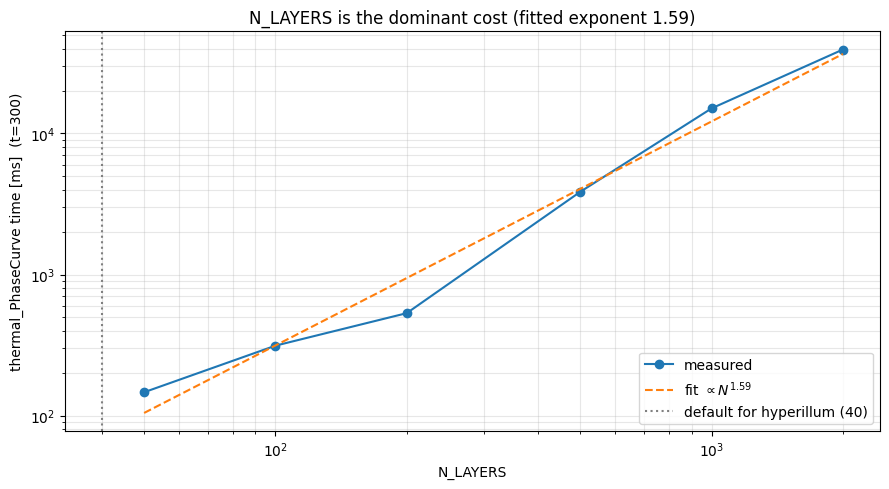

In [4]:
NL_vals = [50, 100, 200, 500, 1000, 2000]
t_grid  = np.linspace(0., period, 300)
NL_times = [time_tpc(N_LAYERS=nl, t=t_grid) for nl in NL_vals]
for nl, ms in zip(NL_vals, NL_times): print(f"  N_LAYERS={nl:4d}: {ms:8.1f} ms")

NLa = np.array(NL_vals, float); msa = np.array(NL_times); sel = NLa >= 20
slope, intc = np.polyfit(np.log(NLa[sel]), np.log(msa[sel]), 1)
print(f"\npower-law exponent (N_LAYERS>=20): {slope:.2f}   (2.0 = perfectly quadratic)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(NL_vals, NL_times, "o-", label="measured")
ax.loglog(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(40, color="grey", ls=":", label="default for hyperillum (40)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title(f"N_LAYERS is the dominant cost (fitted exponent {slope:.2f})"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 3. `len(t)`: number of time samples

The exact path grows linearly with `len(t)`; the fast path evaluates SPIDERMAN only at its phase nodes and in the ingress/egress ramps (section 6) and barely grows. Both at `N_LAYERS=30`.

  len(t)=  100: fast    113.7 ms   normal    101.5 ms
  len(t)=  300: fast    118.7 ms   normal    143.9 ms
  len(t)=  600: fast    121.9 ms   normal    214.3 ms
  len(t)= 1000: fast    140.9 ms   normal    286.9 ms
  len(t)= 2000: fast    108.7 ms   normal    453.1 ms
  len(t)= 4000: fast    126.2 ms   normal    821.6 ms


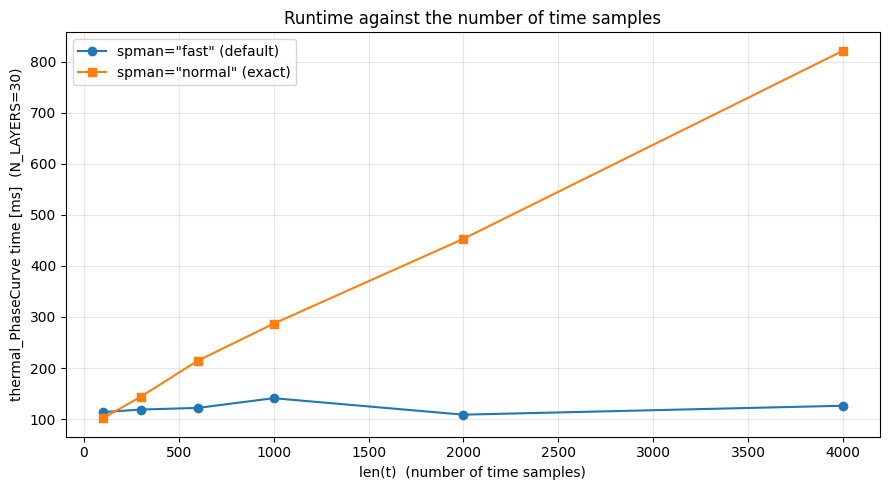

In [5]:
nt_vals  = [100, 300, 600, 1000, 2000, 4000]
nt_fast   = [time_tpc(N_LAYERS=30, t=np.linspace(0., period, n)) for n in nt_vals]                    # default spman="fast"
nt_normal = [time_tpc(N_LAYERS=30, t=np.linspace(0., period, n), spman="normal") for n in nt_vals]     # exact path
for n, f_ms, e_ms in zip(nt_vals, nt_fast, nt_normal): print(f"  len(t)={n:5d}: fast {f_ms:8.1f} ms   normal {e_ms:8.1f} ms")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(nt_vals, nt_fast, "o-", label='spman="fast" (default)')
ax.plot(nt_vals, nt_normal, "s-", label='spman="normal" (exact)')
ax.set_xlabel("len(t)  (number of time samples)"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (N_LAYERS=30)")
ax.set_title("Runtime against the number of time samples"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. Convergence with `N_LAYERS`

Each model's phase curve against a ground truth at `N_LAYERS = 240` on the same time grid: RMS and maximum deviation, and the error of the occultation depth.

ground truth: N_LAYERS = 240   (f_p [ppm]: naive = 189.59, hyperillum = 192.84, louden = 189.60)

  naive     : RMS deviation ~ N_LAYERS^-1.67   (RMS ~ 0.030 ppm at its default N_LAYERS = 60)
  hyperillum: RMS deviation ~ N_LAYERS^-1.61   (RMS ~ 0.063 ppm at its default N_LAYERS = 40)
  louden    : RMS deviation ~ N_LAYERS^-1.67   (RMS ~ 0.031 ppm at its default N_LAYERS = 60)


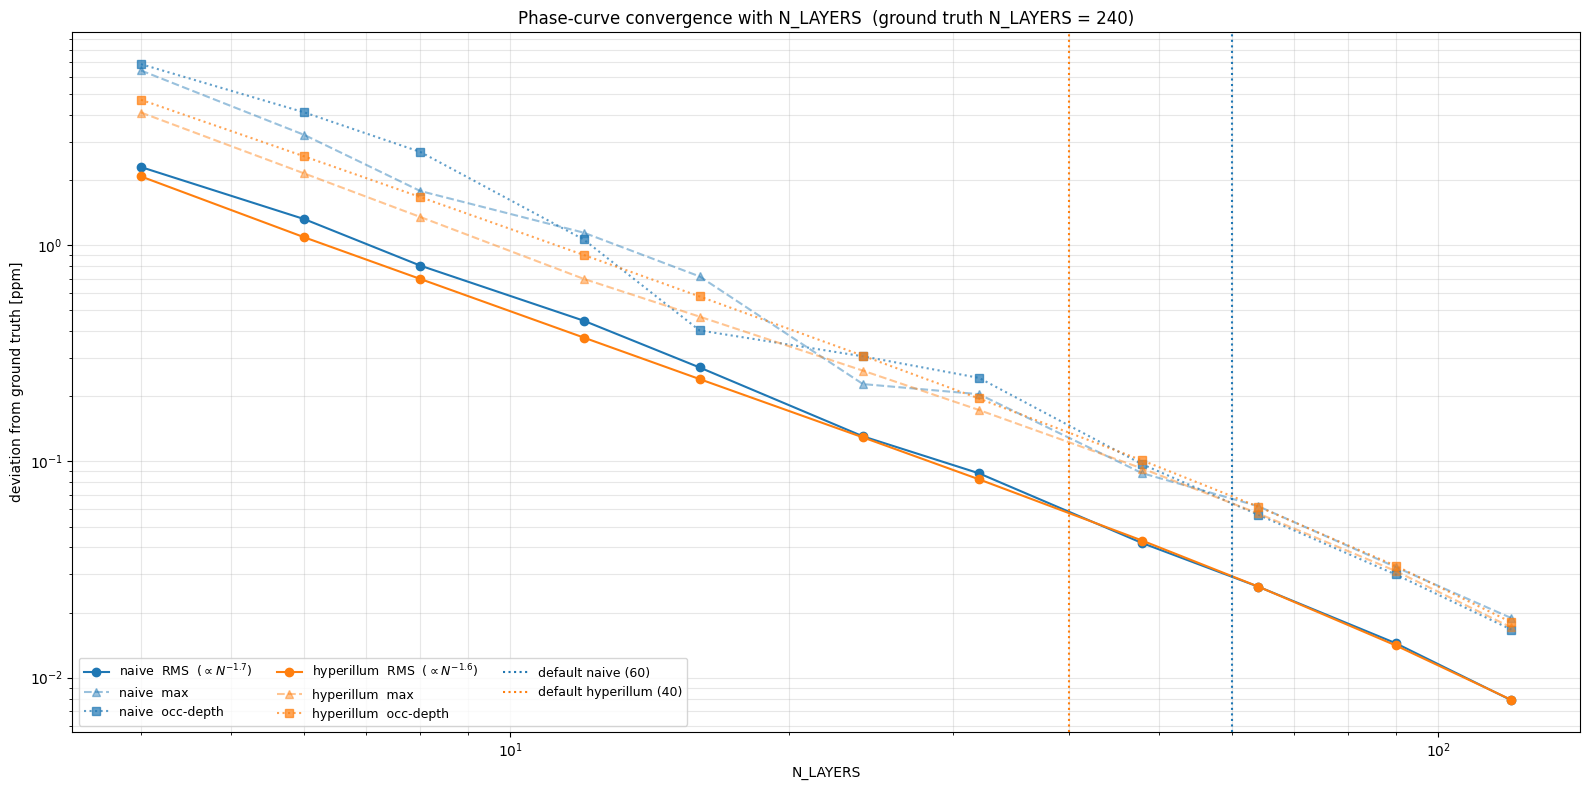

In [6]:
# Convergence of the phase curve with N_LAYERS, vs a high-N_LAYERS ground truth, for all three models
t_conv  = np.linspace(0., period, 200)               # shared grid -> curves differ only through N_LAYERS
NL_GT   = 240                                        # ground-truth reference resolution
NL_conv = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 90, 120])

def _phasecurve(model, nl):
    if model == "louden":   # separate SPIDERMAN model (analytic F=0 map); u left at its default
        return Louden_PhaseCurve(planet, lambda_range, t=t_conv, A_B=A_B, filter_path=filter_path, N_LAYERS=nl)
    return thermal_PhaseCurve(planet, lambda_range, t=t_conv, u=u, A_B=A_B, filter_path=filter_path,
                              insolation_model=model, N_LAYERS=nl, u_bol=u_bol)

conv = {}
for model in ["naive", "hyperillum", "louden"]:
    _, pc_gt, fp_gt, _ = _phasecurve(model, NL_GT)
    rms, mx, fperr = [], [], []
    for nl in NL_conv:
        _, pc, fp, _ = _phasecurve(model, int(nl))
        d = (pc - pc_gt) * 1e6                        # pointwise deviation [ppm]
        rms.append(np.sqrt(np.mean(d**2))); mx.append(np.abs(d).max()); fperr.append(abs(fp - fp_gt))
    conv[model] = dict(rms=np.array(rms), mx=np.array(mx), fperr=np.array(fperr), fp_gt=fp_gt)

print(f"ground truth: N_LAYERS = {NL_GT}   (f_p [ppm]: " + ", ".join(f"{m} = {conv[m]['fp_gt']:.2f}" for m in conv) + ")\n")
rate = {}
N_DEFAULT = {"naive": 60, "hyperillum": 40, "louden": 60}   # defaults of thermal_PhaseCurve (per model) and Louden_PhaseCurve
for model in ["naive", "hyperillum", "louden"]:
    slope, _ = np.polyfit(np.log(NL_conv), np.log(conv[model]["rms"]), 1)
    rate[model] = -slope
    i_def = np.interp(N_DEFAULT[model], NL_conv, conv[model]["rms"])
    print(f"  {model:10s}: RMS deviation ~ N_LAYERS^-{-slope:.2f}   (RMS ~ {i_def:.3f} ppm at its default N_LAYERS = {N_DEFAULT[model]})")

plt.figure(figsize=(16, 8))
for model, c in [("naive", "C0"), ("hyperillum", "C1")]: # , ("louden", "C2")
    plt.loglog(NL_conv, conv[model]["rms"],   "o-",  color=c, label=fr"{model}  RMS  ($\propto N^{{-{rate[model]:.1f}}}$)")
    plt.loglog(NL_conv, conv[model]["mx"],    "^--", color=c, alpha=.45, label=f"{model}  max")
    plt.loglog(NL_conv, conv[model]["fperr"], "s:",  color=c, alpha=.7,  label=f"{model}  occ-depth")
plt.axvline(N_DEFAULT["naive"], color="C0", ls=":", label=f"default naive ({N_DEFAULT['naive']})")
plt.axvline(N_DEFAULT["hyperillum"], color="C1", ls=":", label=f"default hyperillum ({N_DEFAULT['hyperillum']})")
plt.xlabel("N_LAYERS"); plt.ylabel("deviation from ground truth [ppm]")
plt.title(f"Phase-curve convergence with N_LAYERS  (ground truth N_LAYERS = {NL_GT})")
plt.grid(which="both", alpha=.3); plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

## 5. Convergence of the $A_B$ bias

The noiseless $A_B$-only fit (`fit_naive`) with one numerical setting changed at a time from a converged reference (`N_LAYERS`, time samples `n_t`, map grid, fit tolerance); the printed span shows which setting matters.

converged bias (n_layers=120, n_t=2700, grid=600x300, xatol=0.0001) = -0.0465

knob             swept range  bias span   meaning
n_layers           20 -> 120     0.0006   disk shells
n_t               27 -> 2700     0.0125   time samples
n_lo               50 -> 600     0.0021   lon grid pts
xatol         0.03 -> 0.0001     0.0010   fit tolerance


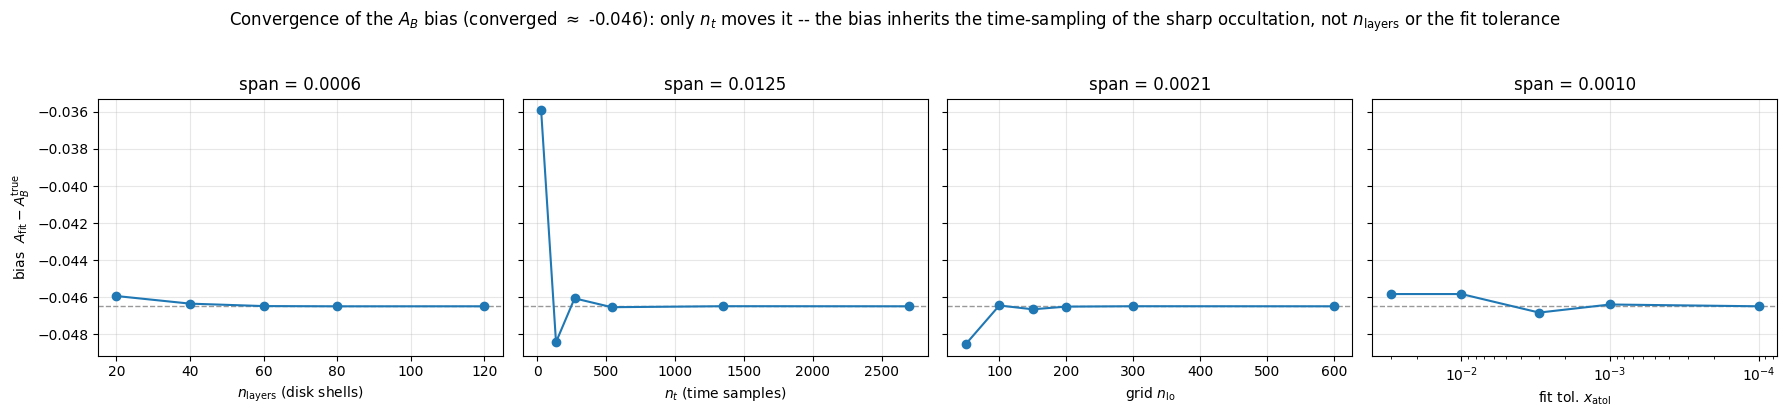

In [7]:
REF  = dict(n_layers=120, n_t=100*n_bins, n_lo=600, n_la=300)   # converged reference
XREF = 1e-4                                              # tight fit tolerance

def conv_bias(xatol=XREF, **over):
    kw = {**REF, **over}
    _, tr    = model_pcurve(cfg, "hyperillum", A_B_true, **kw)
    A_fit, _, _ = fit_naive(cfg, tr, xatol=xatol, **kw)          # free_offset=True (default)
    return A_fit - A_B_true

# one knob varied per sweep
sweeps = {
    "n_layers": [dict(n_layers=v)            for v in (20, 40, 60, 80, 120)],
    "n_t":      [dict(n_t=v)                 for v in np.array([1, 5, 10, 20, 50, 100])*n_bins],
    "n_lo":     [dict(n_lo=v, n_la=v // 2)   for v in (50, 100, 150, 200, 300, 600)],
    "xatol":    [dict(xatol=v)               for v in (3e-2, 1e-2, 3e-3, 1e-3, 1e-4)],
}
key_of = {"n_layers": "n_layers", "n_t": "n_t", "n_lo": "n_lo", "xatol": "xatol"}
flat   = [(name, over) for name, lst in sweeps.items() for over in lst]

vals = Parallel(n_jobs=-1, backend="loky")(delayed(conv_bias)(**over) for _, over in flat)
get_reusable_executor().shutdown(wait=True)  # release the allocator memory accumulated in the SPIDERMAN workers

results = {name: [] for name in sweeps}
for (name, over), b in zip(flat, vals):
    x = over.get(key_of[name], REF.get(key_of[name], XREF))
    results[name].append((x, b))

bias_ref = dict(results["n_t"])[REF["n_t"]]              # bias at the reference config
print(f"converged bias (n_layers={REF['n_layers']}, n_t={REF['n_t']}, grid={REF['n_lo']}x{REF['n_la']}, xatol={XREF:g}) = {bias_ref:+.4f}\n")
print(f"{'knob':9s} {'swept range':>18s} {'bias span':>10s}   meaning")
labels = {"n_layers":"disk shells","n_t":"time samples","n_lo":"lon grid pts","xatol":"fit tolerance"}
for name in sweeps:
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    span = max(ys) - min(ys)
    rng  = f"{xs[0]:g} -> {xs[-1]:g}"
    print(f"{name:9s} {rng:>18s} {span:>10.4f}   {labels[name]}")

# the variation lives almost entirely in n_t; n_layers / grid / fit-tol are flat
panels = [("n_layers", r"$n_\mathrm{layers}$ (disk shells)", False),
          ("n_t",      r"$n_t$ (time samples)",              False),
          ("n_lo",     r"grid $n_\mathrm{lo}$",              False),
          ("xatol",    r"fit tol. $x_\mathrm{atol}$",        True)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, xlabel, logx) in zip(axes, panels):
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    ax.axhline(bias_ref, color="0.6", ls="--", lw=1, zorder=1)
    ax.plot(xs, ys, "-o", color="C0", lw=1.5, ms=6, zorder=2)
    if logx: ax.set_xscale("log"); ax.invert_xaxis()    # tighter tolerance -> right
    ax.set_xlabel(xlabel); ax.grid(alpha=.3)
    ax.set_title(f"span = {max(ys) - min(ys):.4f}")
axes[0].set_ylabel(r"bias  $A_\mathrm{fit}-A_B^\mathrm{true}$")
fig.suptitle(rf"Convergence of the $A_B$ bias (converged $\approx$ {bias_ref:+.3f}): "
             r"only $n_t$ moves it -- the bias inherits the time-sampling of the sharp "
             r"occultation, not $n_\mathrm{layers}$ or the fit tolerance", y=1.03)
fig.tight_layout()
plt.show()

## 6. Accuracy of the fast path

`spman="fast"` (default, `fast_lightcurve`) interpolates the out-of-occultation phase modulation from `n_phase` nodes, evaluates the ingress and egress ramps exactly and skips SPIDERMAN during totality, where the flux is exactly stellar; `spman="normal"` evaluates every time sample. Skipping totality changes no bit (asserted). `spman_kw` sets `n_phase`, `pad` and `split_totality`.

hyperillum N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0034 ppm, rms = 0.0006 ppm,  fp fast/normal = 192.910/192.910 ppm  |  SPIDERMAN evals 1000 -> 40+148 (no split) -> 40+26 (split)  |  split == no-split bit-for-bit: True


naive      N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0321 ppm, rms = 0.0055 ppm,  fp fast/normal = 189.668/189.668 ppm  |  SPIDERMAN evals 1000 -> 40+148 (no split) -> 40+26 (split)  |  split == no-split bit-for-bit: True


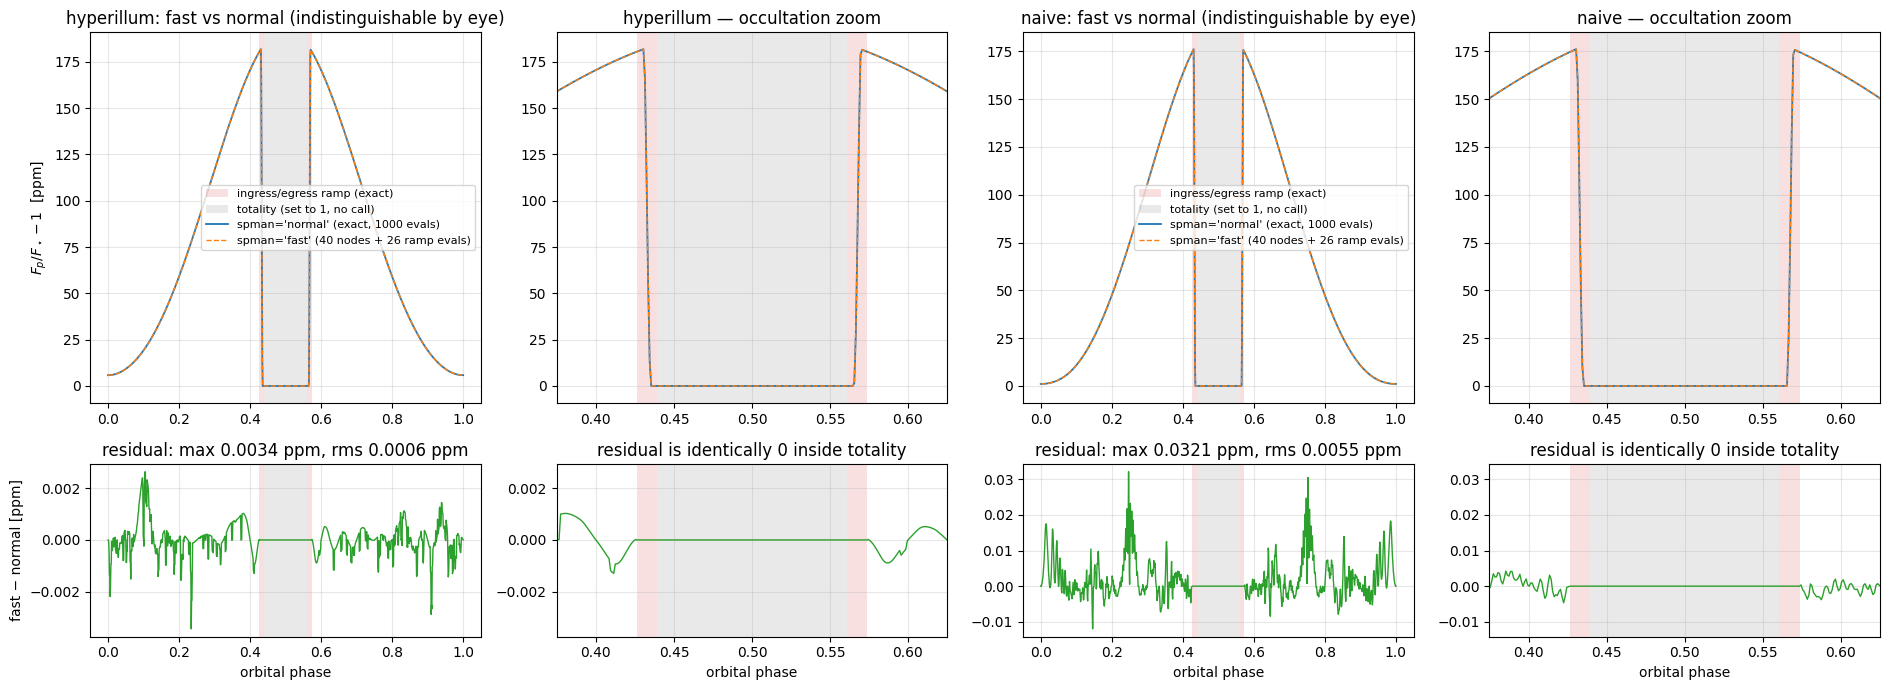

In [8]:
# reference config: overlay fast vs normal and show the residual, for BOTH illumination models
N_LAYERS, N, PAD = 60, 1000, 0.03   # PAD must match fast_lightcurve's `pad`: it sets both the shading below and the totality the split skips
tt = np.linspace(0., period, N)

def tpc(model, **kw):
    return thermal_PhaseCurve(planet, lambda_range, t=tt, u=u, A_B=A_B, filter_path=filter_path,
                              N_LAYERS=N_LAYERS, insolation_model=model, include_transit=False, u_bol=u_bol, **kw)

fig, ax = plt.subplots(2, 4, figsize=(19, 7), gridspec_kw=dict(height_ratios=[3, 1.4]))
for j, model in enumerate(("hyperillum", "naive")):
    _, pc_norm,  fp_norm, sp_n = tpc(model, spman="normal")
    _, pc_fast,  fp_fast, _    = tpc(model, spman="fast")
    _, pc_whole, _,       _    = tpc(model, spman="fast", spman_kw=dict(split_totality=False))  # no totality split: whole padded window exact
    resid = (pc_fast - pc_norm) * 1e6                    # ppm

    t_in, t_out = occultation_window(sp_n, pad=PAD)
    T14, T23    = occultation_durations(sp_n)
    t_occ, half_tot = 0.5 * (t_in + t_out), 0.5 * T23 - PAD * T14   # the totality half-width fast_lightcurve actually skips
    n_ramp = int(((tt >= t_in) & (tt <= t_out) & (np.abs(tt - t_occ) >= half_tot)).sum())
    n_win  = int(((tt >= t_in) & (tt <= t_out)).sum())
    print(f"{model:10s} N_LAYERS={N_LAYERS}, len(t)={N}:  max|Δ| = {np.abs(resid).max():.4f} ppm, rms = {np.sqrt((resid**2).mean()):.4f} ppm,  "
          f"fp fast/normal = {fp_fast:.3f}/{fp_norm:.3f} ppm  |  SPIDERMAN evals {N} -> 40+{n_win} (no split) -> 40+{n_ramp} (split)  |  "
          f"split == no-split bit-for-bit: {np.array_equal(pc_fast, pc_whole)}")

    # three shaded regimes; drawn on the full-orbit column AND the zoom column
    bands = [(t_in, t_occ - half_tot, "C3", "ingress/egress ramp (exact)"), (t_occ + half_tot, t_out, "C3", None),
             (t_occ - half_tot, t_occ + half_tot, "0.4", "totality (set to 1, no call)")]
    for col, zoom in ((2 * j, False), (2 * j + 1, True)):
        for row in (0, 1):
            for lo, hi, c, lab in bands:
                ax[row, col].axvspan(lo / period, hi / period, color=c, alpha=.14, lw=0, label=lab if row == 0 else None)
            ax[row, col].grid(alpha=.3)
            if zoom: ax[row, col].set_xlim((t_in - 0.35 * (t_out - t_in)) / period, (t_out + 0.35 * (t_out - t_in)) / period)
        ax[0, col].plot(tt / period, pc_norm * 1e6, color="C0", lw=1.3, label=f"spman='normal' (exact, {N} evals)")
        ax[0, col].plot(tt / period, pc_fast * 1e6, color="C1", lw=1.0, ls="--", label=f"spman='fast' (40 nodes + {n_ramp} ramp evals)")
        ax[1, col].plot(tt / period, resid, color="C2", lw=1)
        ax[1, col].set_xlabel("orbital phase")
        ax[0, col].set_title(f"{model}{' — occultation zoom' if zoom else ': fast vs normal (indistinguishable by eye)'}")
        ax[1, col].set_title(f"residual: max {np.abs(resid).max():.4f} ppm, rms {np.sqrt((resid**2).mean()):.4f} ppm" if not zoom
                             else "residual is identically 0 inside totality")
    ax[0, 2 * j].legend(fontsize=8)
ax[0, 0].set_ylabel(r"$F_p/F_\star - 1$  [ppm]")
ax[1, 0].set_ylabel("fast − normal [ppm]")
plt.tight_layout(); plt.show()

split_totality bit-identical at all 22 configurations (assert above never fired)


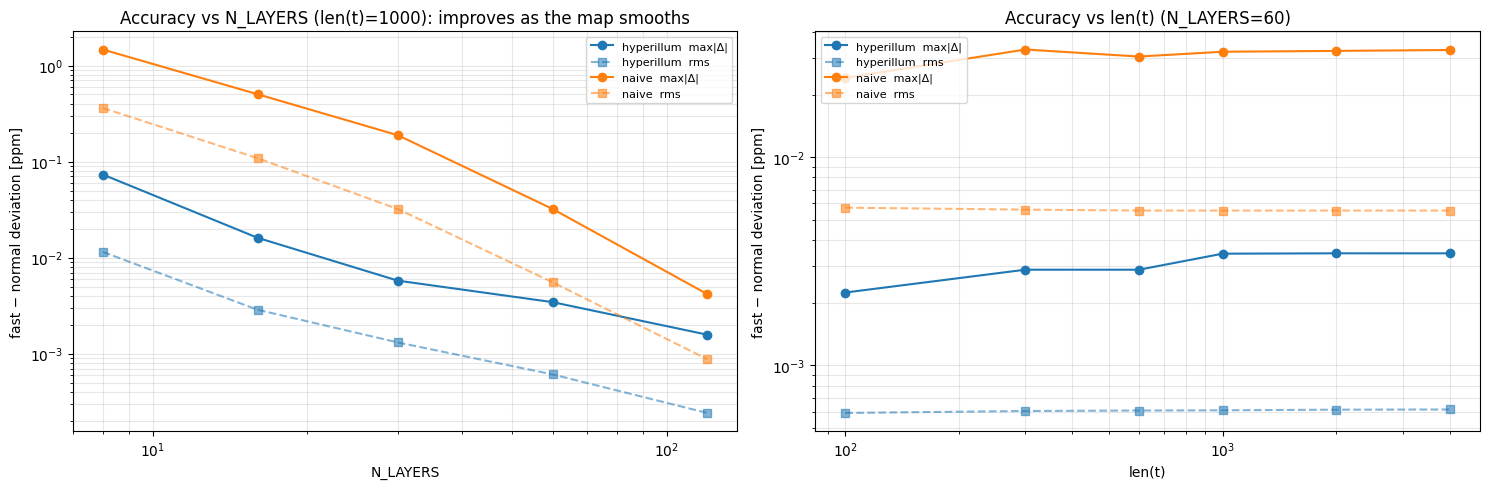

In [9]:
# accuracy of 'fast' vs 'normal' as a function of N_LAYERS and len(t), for both illumination models.
# The third call re-runs 'fast' with the totality split OFF: the split must not move a single bit, only the runtime.
def spman_accuracy(NL, N, model):
    t_ = np.linspace(0., period, N)
    def tpc(**kw): return thermal_PhaseCurve(planet, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                             N_LAYERS=NL, insolation_model=model, include_transit=False, u_bol=u_bol, **kw)[1]
    pn, pf, pw = tpc(spman="normal"), tpc(spman="fast"), tpc(spman="fast", spman_kw=dict(split_totality=False))
    assert np.array_equal(pf, pw), f"split_totality changed the result at N_LAYERS={NL}, len(t)={N}, {model}"
    d = np.abs(pf - pn) * 1e6
    return d.max(), np.sqrt((d ** 2).mean())

NL_vals = [8, 16, 30, 60, 120]
nt_vals = [100, 300, 600, 1000, 2000, 4000]
acc_NL = {m: np.array([spman_accuracy(NL, 1000, m) for NL in NL_vals]) for m in ("hyperillum", "naive")}   # rows: [max|Δ|, rms]
acc_nt = {m: np.array([spman_accuracy(60, N, m) for N in nt_vals]) for m in ("hyperillum", "naive")}
print(f"split_totality bit-identical at all {2 * (len(NL_vals) + len(nt_vals))} configurations (assert above never fired)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for m, c in (("hyperillum", "C0"), ("naive", "C1")):
    # left: vs N_LAYERS -- deviation falls as the disk map (and thus the phase modulation) smooths
    ax[0].loglog(NL_vals, acc_NL[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[0].loglog(NL_vals, acc_NL[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
    # right: vs len(t) -- flat (the interpolation error is a function of orbital phase, not sampling)
    ax[1].loglog(nt_vals, acc_nt[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[1].loglog(nt_vals, acc_nt[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("fast − normal deviation [ppm]")
ax[0].set_title("Accuracy vs N_LAYERS (len(t)=1000): improves as the map smooths")
ax[0].grid(which="both", alpha=.3); ax[0].legend(fontsize=8)
ax[1].set_xlabel("len(t)"); ax[1].set_ylabel("fast − normal deviation [ppm]")
ax[1].set_title("Accuracy vs len(t) (N_LAYERS=60)")
ax[1].grid(which="both", alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. `fspiderman` vs upstream `spiderman`

`fspiderman` (`sp`, [github.com/JonasSpiller/fSPIDERMAN](https://github.com/JonasSpiller/fSPIDERMAN)) is the SPIDERMAN fork the pipeline uses, `spiderman` (`sp_upstream`) upstream with compatibility fixes only. Both run the same exact `lightcurve()` on the same inputs, which isolates the fork's C-level speed patch (patch 2 of its README).

Upstream SPIDERMAN is not part of the environment: its PyPI wheel does not work with numpy ≥ 2, and its source does not build there. `validation/spiderman_numpy2.patch` makes the source build and run without changing its results (its header lists the changes). This section needs it installed next to `fspiderman` (the module names differ):

```bash
git clone https://github.com/tomlouden/spiderman.git
cd spiderman
git checkout 379a5b6
git apply /path/to/HyperPhase/validation/spiderman_numpy2.patch
pip install .
```

hyperillum N_LAYERS=60, len(t)=1000:  max|Δ| = 0.00497 ppm,  rms = 0.00106 ppm


naive  N_LAYERS=60, len(t)=1000:  max|Δ| = 0.00015 ppm,  rms = 0.00006 ppm


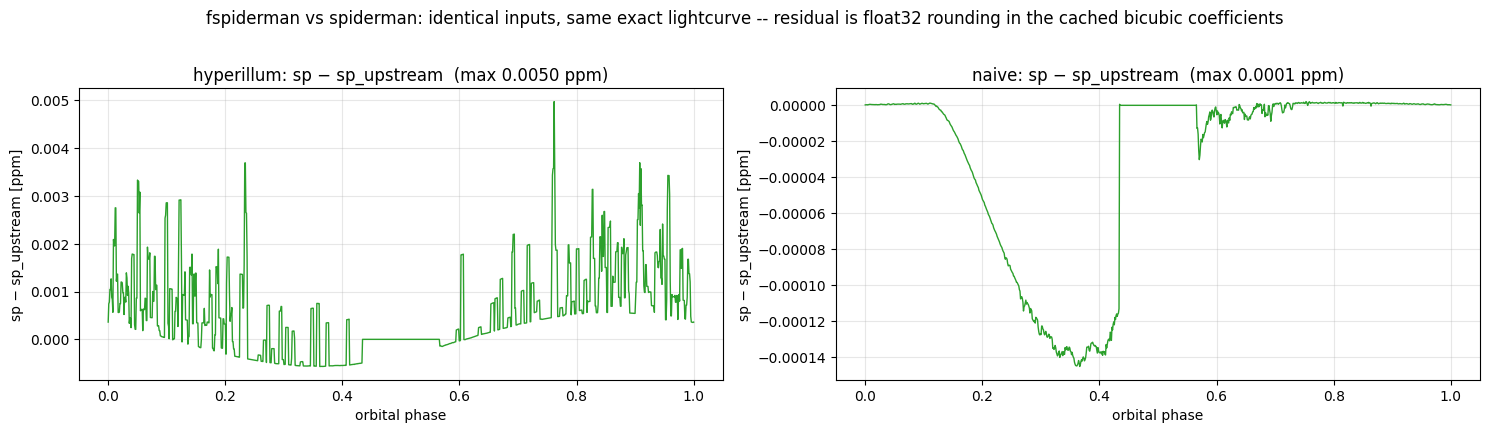

In [10]:
with contextlib.redirect_stdout(io.StringIO()):   # mute "no spidermanrc file detected"
    import spiderman as sp_upstream   # upstream SPIDERMAN with the compatibility patch only (installation: see above)

# Build the thermal_PhaseCurve direct_T model with a given library and return its lightcurve [ppm]. Same inputs for sp_upstream and sp -> isolates the C patches.
# T_floor: the plain spiderman baseline (sp_upstream) has no bicubic clamp and exits on the negative overshoot below a 0 K nightside, so BOTH libraries get the same
# 100 K floor here (fspiderman itself needs none; the pipeline runs unfloored maps). The floor changes both curves alike and cancels in the difference.
_comp_cache = {}
def _compensated_filter(path):
    """Temporary copy of a throughput file with T * lambda_um^2, the pre-compensation upstream spiderman's inverted get_filter factor needs (fspiderman corrects it, fork README patch 6)."""
    if path not in _comp_cache:
        w, T = np.loadtxt(path, unpack=True); tmp = tempfile.NamedTemporaryFile("w", suffix=".dat", delete=False)
        np.savetxt(tmp, np.c_[w, T * (w * 1e6) ** 2], fmt="%.10e %.10e"); tmp.close(); _comp_cache[path] = tmp.name
    return _comp_cache[path]

def lc_lib(lib, model, N_LAYERS=60, nt=1000, n_lo=200, n_la=100, T_floor=100., time_it=False):
    lo, la, Tg = custom_temperature_grid(planet, u_bol=u_bol, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B)
    LO, LA = np.meshgrid(lo, la, indexing="ij")
    p = lib.ModelParams(brightness_model="direct_T", stellar_model="blackbody")
    p.n_layers = N_LAYERS; p.t0 = 0.; p.per = period; p.a_abs = a_AU
    p.inc, p.ecc, p.w = incl, ecc, w; p.rp, p.a = r1 / r2, R / r2; p.p_u1 = p.p_u2 = 0.
    p.T_s = T_eff; p.l1, p.l2 = lambda_range
    p.grid = lib.format_grid(LO, LA, np.maximum(Tg, T_floor).T)
    fpath = filter_path if lib is sp else _compensated_filter(filter_path)   # sp_upstream: upstream get_filter divides by lambda instead of multiplying -> pre-multiply the file by lambda^2 so both libraries weight the band identically
    p.filter, p.eclipse = fpath, True
    with contextlib.redirect_stdout(io.StringIO()):
        sg = lib.stellar_grid.gen_grid(p.l1, p.l2, logg=4.5, response=fpath)
    t = np.linspace(0., period, nt)
    lc = (p.lightcurve(t, stellar_grid=sg) - 1) * 1e6
    if time_it:
        return lc, bench(lambda: p.lightcurve(t, stellar_grid=sg), repeats=1)
    return lc

# accuracy at a reference config (N_LAYERS=60, len(t)=1000), for both illumination models
tt = np.linspace(0., period, 1000)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for j, model in enumerate(("hyperillum", "naive")):
    lc_s, lc_f = lc_lib(sp_upstream, model), lc_lib(sp, model)
    d = lc_f - lc_s
    print(f"{model:6s} N_LAYERS=60, len(t)=1000:  max|Δ| = {np.abs(d).max():.5f} ppm,  rms = {np.sqrt((d**2).mean()):.5f} ppm")
    ax[j].plot(tt/period, d, color="C2", lw=1)
    ax[j].set_title(f"{model}: sp − sp_upstream  (max {np.abs(d).max():.4f} ppm)")
    ax[j].set_xlabel("orbital phase"); ax[j].set_ylabel("sp − sp_upstream [ppm]"); ax[j].grid(alpha=.3)
fig.suptitle("fspiderman vs spiderman: identical inputs, same exact lightcurve -- "
             "residual is float32 rounding in the cached bicubic coefficients", y=1.02)
plt.tight_layout(); plt.show()

  N_LAYERS=   8:  spiderman =     58.6 ms   fspiderman =     15.8 ms   speedup = 3.70x
  N_LAYERS=  16:  spiderman =    228.5 ms   fspiderman =     53.7 ms   speedup = 4.26x
  N_LAYERS=  30:  spiderman =    811.4 ms   fspiderman =    188.5 ms   speedup = 4.31x
  N_LAYERS=  60:  spiderman =   3160.9 ms   fspiderman =    723.3 ms   speedup = 4.37x
  N_LAYERS= 120:  spiderman =  13224.2 ms   fspiderman =   4027.4 ms   speedup = 3.28x


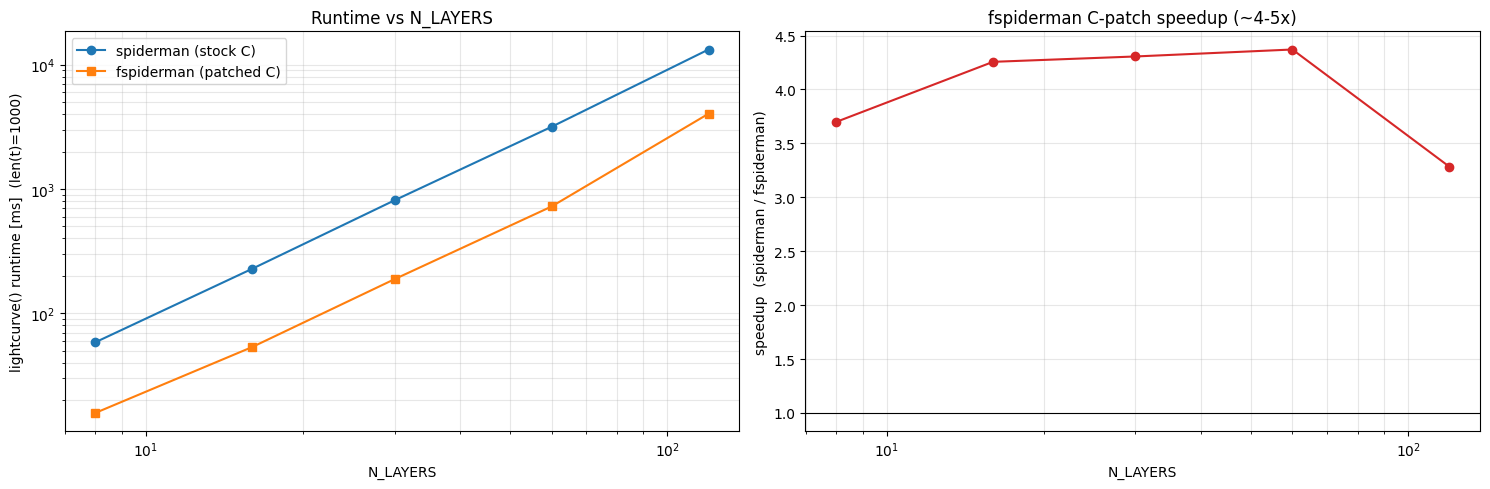

In [11]:
# runtime: Stock spiderman vs fspiderman, exact lightcurve() vs N_LAYERS at len(t)=1000
NL_rt = [8, 16, 30, 60, 120]
t_s  = [lc_lib(sp_upstream, "hyperillum", N_LAYERS=NL, time_it=True)[1] for NL in NL_rt]
t_f = [lc_lib(sp, "hyperillum", N_LAYERS=NL, time_it=True)[1] for NL in NL_rt]
for NL, s, f in zip(NL_rt, t_s, t_f):
    print(f"  N_LAYERS={NL:4d}:  spiderman = {s:8.1f} ms   fspiderman = {f:8.1f} ms   speedup = {s/f:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(NL_rt, t_s,  "o-", label="spiderman (stock C)")
ax[0].loglog(NL_rt, t_f, "s-", label="fspiderman (patched C)")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("lightcurve() runtime [ms]  (len(t)=1000)")
ax[0].set_title("Runtime vs N_LAYERS"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(NL_rt, np.array(t_s) / np.array(t_f), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8)
ax[1].set_xlabel("N_LAYERS"); ax[1].set_ylabel("speedup  (spiderman / fspiderman)")
ax[1].set_title("fspiderman C-patch speedup (~4-5x)"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); plt.show()